<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/FraudDetectionTransactions_UnSupper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

unsupervised learning model, [ Anomaly Detection]


1.   Isolation Forest
2.   DBSCAN
3.   K-Means Clustering

In [37]:
#https://www.kaggle.com/datasets/aryan208/financial-transactions-dataset-for-fraud-detection/data

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
df = pd.read_csv('sample_data/fina_fraud_det_UnSupper.csv')

In [40]:
df.columns

Index(['transaction_id', 'timestamp', 'sender_account', 'receiver_account',
       'amount', 'transaction_type', 'merchant_category', 'location',
       'device_used', 'is_fraud', 'fraud_type', 'time_since_last_transaction',
       'spending_deviation_score', 'velocity_score', 'geo_anomaly_score',
       'payment_channel', 'ip_address', 'device_hash'],
      dtype='object')

In [41]:
# Transaction_Amount
# velocity_score
# geo_anomaly_score
# spending_deviation_score
# time_since_last_transaction
# payment_channel
# device_used
# merchant_category
# location

In [42]:
new_df=df[['amount','velocity_score','geo_anomaly_score','spending_deviation_score','time_since_last_transaction','payment_channel','device_used','merchant_category','location']]

In [43]:
new_df

,amount,velocity_score,geo_anomaly_score,spending_deviation_score,time_since_last_transaction,payment_channel,device_used,merchant_category,location
0,343.78,3,0.22,-0.21,NaN,card,mobile,utilities,Tokyo
1,419.65,7,0.96,-0.14,NaN,ACH,atm,online,Toronto
2,2773.86,20,0.89,-1.78,NaN,card,pos,other,London
3,1666.22,6,0.37,-0.60,NaN,wire_transfer,pos,online,Sydney
4,24.43,13,0.27,0.79,NaN,ACH,mobile,utilities,Toronto
...,...,...,...,...,...,...,...,...,...
4999995,10.87,17,0.18,-0.14,1416.524233,UPI,atm,retail,Toronto
4999996,181.40,4,0.58,-1.79,999.089702,wire_transfer,atm,grocery,Sydney
4999997,12.54,6,0.99,-0.30,3871.584025,card,mobile,utilities,New York
4999998,376.29,5,0.32,-1.43,-4096.765453,wire_transfer,pos,restaurant,Dubai


In [44]:
new_df.describe()

,amount,velocity_score,geo_anomaly_score,spending_deviation_score,time_since_last_transaction
count,5.000000e+06,5.000000e+06,5.000000e+06,5.000000e+06,4.103487e+06
mean,3.589343e+02,1.050132e+01,5.000293e-01,-3.881160e-04,1.525799e+00
std,4.699333e+02,5.766842e+00,2.886349e-01,1.000807e+00,3.576569e+03
min,1.000000e-02,1.000000e+00,0.000000e+00,-5.260000e+00,-8.777814e+03
25%,2.657000e+01,5.000000e+00,2.500000e-01,-6.800000e-01,-2.562376e+03
50%,1.386700e+02,1.100000e+01,5.000000e-01,0.000000e+00,8.442747e-01
75%,5.038900e+02,1.600000e+01,7.500000e-01,6.700000e-01,2.568339e+03
max,3.520570e+03,2.000000e+01,1.000000e+00,5.020000e+00,8.757758e+03


In [45]:
new_df.duplicated().sum()

np.int64(0)

In [46]:
new_df.isna().sum()

,0
amount,0
velocity_score,0
geo_anomaly_score,0
spending_deviation_score,0
time_since_last_transaction,896513
payment_channel,0
device_used,0
merchant_category,0
location,0


In [47]:
missing_pct = (new_df['time_since_last_transaction'].isna().sum() / len(new_df)) * 100
print(f"{missing_pct:.2f}%")

17.93%


In [48]:
new_df['time_since_last_transaction']=new_df['time_since_last_transaction'].fillna(new_df['time_since_last_transaction'].median())

/tmp/ipykernel_25671/3335519019.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['time_since_last_transaction']=new_df['time_since_last_transaction'].fillna(new_df['time_since_last_transaction'].median())


In [49]:
missing_pct = (new_df['time_since_last_transaction'].isna().sum() / len(new_df)) * 100
print(f"{missing_pct:.2f}%")

0.00%


In [50]:
new_df.dtypes

,0
amount,float64
velocity_score,int64
geo_anomaly_score,float64
spending_deviation_score,float64
time_since_last_transaction,float64
payment_channel,object
device_used,object
merchant_category,object
location,object


In [51]:
new_df['payment_channel'].unique()

array(['card', 'ACH', 'wire_transfer', 'UPI'], dtype=object)

In [52]:
new_df['device_used'].unique()

array(['mobile', 'atm', 'pos', 'web'], dtype=object)

In [53]:
new_df['merchant_category'].unique()

array(['utilities', 'online', 'other', 'entertainment', 'travel',
       'grocery', 'retail', 'restaurant'], dtype=object)

In [54]:
new_df['location'].unique()

array(['Tokyo', 'Toronto', 'London', 'Sydney', 'Berlin', 'Dubai',
       'New York', 'Singapore'], dtype=object)

In [55]:
new_df=pd.get_dummies(new_df,drop_first=True,dtype=int)

In [56]:
new_df

,amount,velocity_score,geo_anomaly_score,spending_deviation_score,time_since_last_transaction,payment_channel_UPI,payment_channel_card,payment_channel_wire_transfer,device_used_mobile,device_used_pos,...,merchant_category_retail,merchant_category_travel,merchant_category_utilities,location_Dubai,location_London,location_New York,location_Singapore,location_Sydney,location_Tokyo,location_Toronto
0,343.78,3,0.22,-0.21,0.844275,0,1,0,1,0,...,0,0,1,0,0,0,0,0,1,0
1,419.65,7,0.96,-0.14,0.844275,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,2773.86,20,0.89,-1.78,0.844275,0,1,0,0,1,...,0,0,0,0,1,0,0,0,0,0
3,1666.22,6,0.37,-0.60,0.844275,0,0,1,0,1,...,0,0,0,0,0,0,0,1,0,0
4,24.43,13,0.27,0.79,0.844275,0,0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999995,10.87,17,0.18,-0.14,1416.524233,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
4999996,181.40,4,0.58,-1.79,999.089702,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4999997,12.54,6,0.99,-0.30,3871.584025,0,1,0,1,0,...,0,0,1,0,0,1,0,0,0,0
4999998,376.29,5,0.32,-1.43,-4096.765453,0,0,1,0,1,...,0,0,0,1,0,0,0,0,0,0


In [57]:
new_df.duplicated().sum()

np.int64(0)

In [58]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
new_df_Scaled= scaler.fit_transform(new_df)

PCA

In [59]:
from sklearn.decomposition import PCA
pca=PCA().fit(new_df_Scaled)

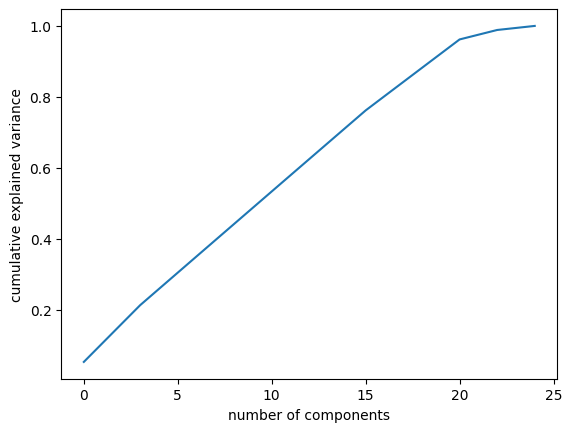

In [60]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()

In [61]:
sk_pca=PCA(n_components=0.95)
new_df_pca=sk_pca.fit_transform(new_df_Scaled)
print(new_df_pca.shape)

(5000000, 21)


In [62]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(
    contamination=0.01,
    random_state=42)

pred = iso.fit_predict(new_df_pca)

In [63]:
pred

array([ 1,  1, -1, ...,  1,  1,  1])

In [64]:
pred = pred.copy()

pred[pred == 1] = 0      # Normal
pred[pred == -1] = 1     # Fraud

In [65]:
from sklearn.metrics import precision_score, recall_score

y_true = df['is_fraud']

precision = precision_score(y_true, pred)
recall = recall_score(y_true, pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.04044
Recall: 0.011261298892249085


Precision = 0.0404  = 4.04%
Recall    = 0.0113  = 1.13%

In [66]:
df['is_fraud'].value_counts(normalize=True)

,proportion
is_fraud,
False,0.964089
True,0.035911


In [67]:
iso = IsolationForest(
    contamination=0.03,
    random_state=42)

pred = iso.fit_predict(new_df_pca)

In [68]:
pred = pred.copy()
pred[pred == 1] = 0      # Normal
pred[pred == -1] = 1     # Fraud
y_true = df['is_fraud']

precision = precision_score(y_true, pred)
recall = recall_score(y_true, pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.0403
Recall: 0.033666939566590365


In [69]:
#Precision = 0.0403 (4.03%)
#Recall    = 0.0337 (3.37%)

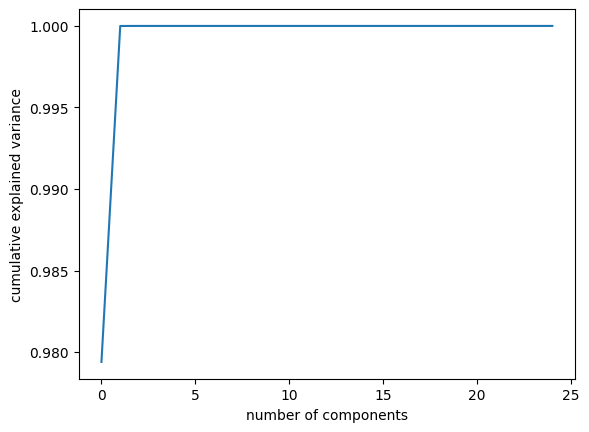

In [70]:
pca=PCA().fit(new_df)  # unscaled data used
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()

In [ ]:
#Isolation Forest Hyperparameter

In [71]:
iso = IsolationForest(
     n_estimators=300,
    contamination=0.01,
    random_state=42)
pred = iso.fit_predict(new_df_pca)

#------------------------------------------
pred = pred.copy()
pred[pred == 1] = 0      # Normal
pred[pred == -1] = 1     # Fraud

#--------------------------------
precision = precision_score(y_true, pred)
recall = recall_score(y_true, pred)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.03996
Recall: 0.011127633623498355


In [ ]:
#DBSCAN